# Лекція 5. Локальний деплоймент і оптимізація моделей

Демо до лекції. Усі моделі в цьому ноутбуці запускаються **локально** через [Ollama](https://ollama.com), їх використання відбувається через HTTP-запити.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [1]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

### 0.1. Встановлюємо й запускаємо Ollama

Локально цю клітинку можна просто виконати: вона нічого не зробить.

In [2]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)

Running in Colab: True
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


### 0.2. Перевіряємо, що Ollama працює

Ollama — це HTTP-сервер на порту 11434. Функція `ollama()` надсилає йому запит і повертає відповідь як словник Python; якщо сервер працює, побачимо його версію.

In [3]:
def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


print("Ollama version:", ollama("/api/version")["version"])

Ollama version: 0.40.16


## 1. Base, Instruct і Thinking

Порівнюємо три поведінки однієї й тієї самої моделі Qwen3 1.7B:
- **Base-модель** пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент.
- **Instruct-модель** додатково донавчили на прикладах «інструкція → відповідь» у форматі діалогу.
- **Thinking** — режим, у якому Instruct-модель перед відповіддю генерує ланцюжок міркувань.

### 1.0. Завантажуємо моделі

Беремо одну й ту саму модель Qwen3 1.7B у двох версіях:
- **Base** — [Qwen3-1.7B-Base](https://huggingface.co/Qwen/Qwen3-1.7B-Base) у форматі GGUF (Q4_K_M) з Hugging Face;
- **Instruct** — офіційна [qwen3:1.7b](https://ollama.com/library/qwen3) з каталогу Ollama; вона ж уміє працювати в режимі міркування.

Перше завантаження займає кілька хвилин.

In [4]:
BASE_MODEL = "hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M"
INSTRUCT_MODEL = "qwen3:1.7b"

for m in (BASE_MODEL, INSTRUCT_MODEL):
    print("pull", m, "→", ollama("/api/pull", {"model": m, "stream": False})["status"])

pull hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M → success
pull qwen3:1.7b → success


### 1.1. Допоміжні функції

Нам вистачить двох ендпойнтів Ollama:
- `/api/generate` з `"raw": true` — передає моделі текст як є, **без chat template**;
- `/api/chat` — приймає список повідомлень і сам загортає їх у chat template моделі.

У Qwen3 режим міркування вмикається параметром `think`. З `think=True` модель спершу генерує ланцюжок міркувань (Ollama повертає його окремим полем `message.thinking`), а вже потім — відповідь. Функція `compare_thinking()` запускає запит в обох режимах і показує відповідь, кількість згенерованих токенів і час.

In [5]:
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

### 1.2. Base: модель просто продовжує текст

Поставимо Base- та Instruct-моделі однакове питання.

In [6]:
QUESTION = "Яка столиця Франції?"

In [7]:
print(generate_raw(BASE_MODEL, QUESTION))

 Як називається найбільша річка Франції? Як називається найбільша річка Франції, яка розташована в Північній Америці? Як називається найбільша річка Франції, яка розташована в Півдні Франції? Як називається найбільша р


Для Base-моделі «Яка столиця Франції?» схоже на початок списку питань вікторини — тож вона продовжує цей список, а не відповідає.

### 1.3. Instruct: модель відповідає на питання

In [8]:
print(chat(INSTRUCT_MODEL, QUESTION)["message"]["content"])

Столиця Франції — це **Париж**.


### 1.4. Instruct проти Thinking: багатокрокова задача

In [9]:
compare_thinking(
    "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, "
    "а потім зʼїла 2 яблука. Скільки яблук у кошику?"
)

=== think=False | токенів: 252 | генерація: 2.0 с
--- відповідь:
Розглянемо ситуацію крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди ще 2 пакети по 4 яблука.**  
   - Кожен пакет містить 4 яблука, тому:
     $$
     2 \text{ пакети} \times 4 \text{ яблука} = 8 \text{ яблука}
     $$
   - Значить, після додавання пакетів у кошик буде:
     $$
     3 + 8 = 11 \text{ яблука}
     $$
3. **Марія зʼїла 2 яблука.**  
   - Після з’ївання:
     $$
     11 - 2 = 9 \text{ яблука}
     $$

**Відповідь:**  
$$
\boxed{9}
$$

=== think=True | токенів: 569 | генерація: 4.7 с
--- міркування (1410 символів), початок:
Okay, let's see. So the problem is about Maria putting some apples in a basket and then eating some. Let me break it down step by step.

First, the basket starts with 3 apples. Then, Maria adds 2 packages, each containing 4 apples. So, I need to calculate how many apples she adds in total. Each package has 4 apples, and there are 2 packages. So that's 2 times 4, which i

Обидва режими відповідають правильно, але з міркуванням модель генерує в кілька разів більше токенів — а користувач бачить відповідь лише після них. Зверніть увагу: міркує модель англійською, хоча питання українською.

### 1.5. Міркування не гарантують правильності

In [10]:
compare_thinking("Скільки разів літера «р» трапляється в слові «трансформер»?")

=== think=False | токенів: 227 | генерація: 1.8 с
--- відповідь:
Щоб визначити, скільки разів літера **«р»** трапляється в слові **«трансформер»**, зробимо так:

Слово: **трансформер**

Розбілем його на складні слова:

- **транс**  
- **формер**

Тепер зіштовхуємо літеру **«р»** в кожному з складних слів:

1. **транс** — не має літери «р»  
2. **формер** — має **1** відтінок «р» (відтінок «р» у слові **формер**)

Отже, літера **«р»** трапляється **1 раз** в слові **«трансформер»**.

**Відповідь: 1 раз.**

=== think=True | токенів: 659 | генерація: 5.5 с
--- міркування (1490 символів), початок:
Okay, let's see. The user is asking how many times the letter "р" appears in the word "трансформер". First, I need to make sure I know the correct spelling of the word. The word in question is "трансформер". Let me write it out: трансформер.

Now, I need to check each letter one by one. Let's start from the beginning. The first letter is "т" which is "t" in Ukrainian, but the question is about th

Правильна відповідь — 3 (т**р**ансфо**р**ме**р**), але мала модель помиляється в обох режимах. Чому так — подумайте самі (це питання до лабораторної роботи).

Спробуйте власні запити: де режим міркування справді допомагає, а де лише витрачає токени?

## 2. Квантизація з Quanto

Завантажимо ту саму модель у чотирьох варіантах — від оригінальних 16 біт до 2 біт — і подивимося, що квантизація змінює в памʼяті, швидкості та якості. Якість перевіримо трьома способами: перплексією, перекладом з автоматичними метриками й очима — на вільній генерації тексту.

**Quanto.** [Optimum Quanto](https://github.com/huggingface/optimum-quanto) — бібліотека квантизації від Hugging Face, один із бекендів [Optimum](https://huggingface.co/docs/optimum). У Transformers вона підключається через [`QuantoConfig`](https://huggingface.co/docs/transformers/quantization/quanto) і квантизує модель прямо під час завантаження, тому окремий файл з квантизованими вагами не потрібен. Квантизуються ваги лінійних шарів (`nn.Linear`) — у них більшість параметрів моделі, а ембединги, нормалізації та вихідний шар лишаються в 16 бітах.

| Варіант | Біт на вагу | Що це |
|---|---|---|
| fp16 | 16 | Оригінальні ваги, точка відліку |
| int8 | 8 | 8-бітні цілі числа з масштабом |
| int4 | 4 | 4-бітні цілі числа, ваги діляться на блоки з власними масштабами |
| int2 | 2 | 2-бітні цілі числа — лише 4 можливі значення на вагу; тут модель має зламатися |

**Обчислення.** Множити числа в цих форматах напряму T4 не вміє, тому перед множенням ваги розпаковуються в 16 біт. Тому памʼяті потрібно менше, а от генерація часто **не прискорюється**, а то й сповільнюється.

**Де запускати.** Секцію запускаємо **в Google Colab на GPU T4** (Runtime → Change runtime type → T4 GPU). Беремо формат **fp16**, а не bf16: T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна.

### 2.0. Встановлюємо бібліотеки й перевіряємо GPU

In [11]:
%pip uninstall -y -q diffusers  # optimum-quanto імпортує diffusers, якщо він є; передвстановлена в Colab версія несумісна з його torchao
%pip install -q "transformers==5.20.1" "accelerate==1.15.0" "optimum-quanto==0.2.7" "evaluate==0.4.6" "sacrebleu==2.6.0"

In [12]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: Tesla T4


### 2.1. Модель і варіанти квантизації

Беремо [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) — сильнішу модель того ж сімейства, що й у секції 1: 4B параметрів, лише Instruct-режим без міркувань. У fp16 вона займає ~8 GB і вміщається в T4 з його 16 GB.

In [13]:
MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

### 2.2. Що міряємо

**Перплексія** — стандартна автоматична метрика якості квантизації (нею міряє, зокрема, llama.cpp). Модель читає фіксований текст, і для кожного токена ми дивимося, яку ймовірність вона йому давала. Перплексія — це, грубо кажучи, з якої кількості варіантів модель у середньому «вагалася»: чим вона менша, тим краще модель знає мову й тему. Еталонних відповідей тут не потрібно, а число змінюється плавно, тому видно навіть невеликі втрати. Порівнювати перплексію можна лише в межах однієї мови: англійська й українська токенізуються по-різному.

**Переклад EN → UK** — реалістичне завдання з генерацією тексту, для якого є еталонні переклади. Порівнюємо переклад моделі з еталоном двома стандартними метриками з бібліотеки [Evaluate](https://huggingface.co/docs/evaluate):
- [**chrF**](https://github.com/huggingface/evaluate/blob/main/metrics/chrf/README.md) — наскільки збігаються послідовності символів (0–100);
- [**BLEU**](https://github.com/huggingface/evaluate/tree/main/metrics/sacrebleu) — наскільки збігаються послідовності слів (0–100). Сувора метрика: синонім чи інший порядок слів уже знижують бал.

**Вільна генерація** — лист, пояснення, план, код. Тут еталону немає, тож оцінюємо очима в 2.5.

Крім якості, для кожного варіанта записуємо **памʼять моделі** на GPU, **пік VRAM** і **швидкість генерації** (tokens/s).

In [14]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

### 2.3. Проганяємо всі варіанти

Дві допоміжні функції — перплексія тексту й генерація відповіді — і цикл по варіантах: завантажуємо модель, міряємо все потрібне, звільняємо памʼять. Займає кілька хвилин на варіант.

In [15]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

fp16: готово


... (2 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int2: готово


### 2.4. Памʼять, швидкість і автоматичні метрики

In [16]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,8.04,8.64,16.35,2.67,2.40,55.22,23.71
int8,4.42,5.01,5.97,2.67,2.40,58.25,26.17
int4,2.73,3.32,2.95,2.81,2.76,55.34,29.79
int2,1.81,2.39,2.99,60091.86,34451480.00,0.19,0.12


Перплексія для кожної мови окремо. Вісь — логарифмічна: інакше на одному графіку не помістилися б і кілька одиниць, і сотні.

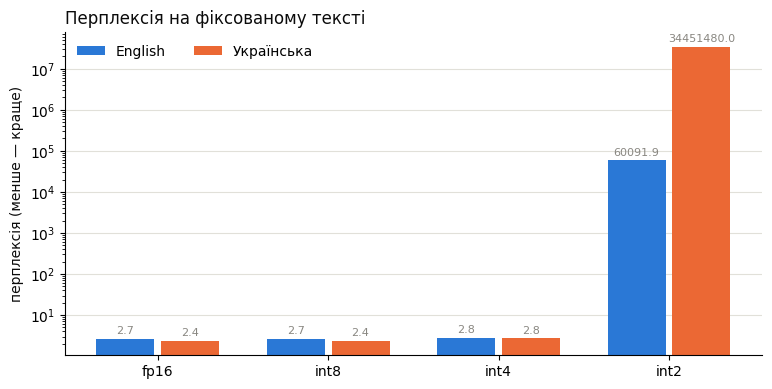

In [17]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Переклади всіх варіантів поруч з еталоном:

In [18]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"Зустріч була перенесена на четвер, о 15 годин.","Зустріч перенесли на четвер, о 15 годин.","Зустріч була перенесена на четвер, о 15 годин.",`` takenosthawkhhhawkoft0houghth``t`\'uleh'thh...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.",Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,takenawns between't```````````````````h``` \`e...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,Бібліотека закривається у неділі та дні відпоч...,Бібліотека закривається у неділі та дні відпоч...,Бібліотека відкрита тільки з 1 по 7.,`ever �house �take caught}}house0}0 taken take...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тести все ще н...",fil}'sand ever0'f}'h \n'}'}''}'' \n' \n \n ...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","Завтра піде дощ, тому взміть засіб.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра буде дощ, тому взміть засіб.",}again \蚊} taken \neverh. \n \nagain \n \n...
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","Новий модель менший, але відповідає почти так ...","Новий модель менший, але відповідає приблизно ...","Новий модель менший, але відповідає почти так ...",fil��''}\n0. between'h ’h ` between betweenfec...
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати стіл для двох на сім годин...,Я бажаю забронювати стіл для двох на сім годин...,Я б хотів зареєструвати стіл для двох на 7 год...,``ever``always```comeight`[\n`letic touched`ev...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та вільний Wi-Fi.,.前所eterminefilosterone0 00 \00 \tt011011OFF00e...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати свою лабораторну робот...,Студенти повинні відправляти лабораторну робот...,he $everearned a0001100evers \n0\n\nhehe0'tou...
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...",ever. taken againoughtbetweenhtonhhofthhbetwee...


### 2.5. Сліпе порівняння: fp16 проти int4

Автоматичні метрики показали, наскільки int4 відрізняється від fp16 у числах. Тепер перевірмо очима — так, як це роблять оцінювачі-люди: для кожного запиту показуємо дві відповіді, fp16 та int4, **у випадковому порядку й без підписів**. Ваше завдання — обрати кращу.

In [19]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**Відповідь A:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**Відповідь B:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

**Відповідь A:**

Квантизація нейромережі — це процес зменшення точності ваг між нейронами в мережі, щоб зменшити об’єм пам’яті та швидкість обчислень. Вона полягає у заміні дробових чисел (наприклад, з плаваючою комою) на цілі числа (наприклад, з кількома бітами). Це дозволяє запускати мережі на пристроях з обмеженою відповідністю, таких як мобільні телефони або IoT-апарати. Насправді, квантизація не втрачає повно

**Відповідь B:**

Квантизація нейромережі — це процес зменшення точності ваг (зв'язків між нейронами) до тих рівнів, що можна зберігати в комп'ютері з меншою відповідністю до об’ємних ресурсів. Це робиться для зменшення об’єму пам’яті та швидкості обчислень. Наприклад, ваги можуть бути зображено як цілі числа (наприклад, 8 біт) замість дробових чисел. Це зручно для використання на пристроях з обмеженими ресурс

... (5 outputs left out)

**Відповідь B:**

Ось чіткий і практичний план підготовки до іспиту з програмування на 5 днів — по одному ключовому темі на день. Цей план призначений для студентів, які вивчають програмування на початковому або середньому рівні (наприклад, на мові Python, Java або C++), але може бути адаптований під будь-яку мову.

---

**День 1: Основні структури даних та їх використання**

- Повторити: змінні, типи даних, оператори, вирази.
- Вивчити: списки, кортежі, слов

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**Відповідь A:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**Відповідь B:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

Для кожного запиту запишіть **"A"** або **"B"** — яка відповідь краща, або **"="**, якщо однакові за якістю. Потім запустіть наступну клітинку, щоб дізнатися, де була яка модель.

In [20]:
VOTES = {1: "B", 2: "B", 3: "=", 4: "B", 5: "="}

In [21]:
if all(v in ("A", "B", "=") for v in VOTES.values()):
    rows = []
    for i, vote in VOTES.items():
        order = dict(zip("AB", BLIND_ORDER[i - 1]))
        rows.append({"запит": GEN_PROMPTS[i - 1], "A": order["A"], "B": order["B"],
                     "ваш вибір": "однаково" if vote == "=" else order[vote]})
    display(pd.DataFrame(rows))
    choices = [r["ваш вибір"] for r in rows]
    print(f"fp16 краща: {choices.count('fp16')}, int4 краща: {choices.count('int4')}, однаково: {choices.count('однаково')}")
else:
    print('Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.')

,запит,A,B,ваш вибір
0,Напиши короткий лист викладачеві з проханням п...,fp16,int4,int4
1,Поясни студентові першого курсу в 3–4 реченнях...,fp16,int4,int4
2,Explain in three sentences why the sky is blue.,fp16,int4,однаково
3,Склади план підготовки до іспиту з програмуван...,int4,fp16,fp16
4,Write a Python function that checks whether a ...,int4,fp16,однаково


fp16 краща: 1, int4 краща: 2, однаково: 2


### 2.6. Відповіді всіх варіантів

Тепер, коли сліпе порівняння зроблено, — відповіді всіх варіантів з підписами, включно з int8 та int2. Еталону тут немає, тож читаємо самі.

In [22]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**int8:**

Ось приклад короткого листа викладачеві:

---

**Дорогий [Ім’я викладача]!**

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу.  
Буду дуже вдячний за розуміння та гнучкість.

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Контактна інформація, якщо потрібно]

---

Цей лист короткий, виразний та відповідає формату прохання. Можна адаптувати під конкретну ситуацію.

**int4:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

**int2:**

°°h\ter°\n h hsd°°ampton \ \
 \
:
h h h h : had had had had had had again had had had had h bettb h hhtonhtonsd**leehtonhtonsdhtonhtonhtonhtonhtonhtonhton (%) nuts9 system \ \ rest  \} \} \n \ \ \ \  \ \ \ \ h \ \ \ h \ \ h \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \  \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ the \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int8:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**int2:**

\
 \'  
\' 
\' \ \ \ \ \\'\' \ \ \ \ \\' \\' \ OFF ** \ - [\'0 \'\'\'\'\'\' \' \ \ \ 
 
  \ 
5  \ \ \\ \ 
 
0 \ -  - - - - - - - - - - -  \ \ - - - - \  
\' \ \\'\' \\'\'    - - sent\'\'\'\'\n\'\' \ \ \ \ \ \ \ \ \ \ \ \ \ \ - - \ -  - -  -\'20\' \' - - - - - - - - - \ \' - -':
 - - - - - - - - - -   - - - - - - - - - - - - - - - - - - - - - -LOCK  \ -  \ -\' \ \ \   PRO \ - - - - - -

## 3. Відповіді на питання (пункт 0.1)

Числа взято з виводів клітинок вище. Клітинки з кодом (Q1, Q5, Q7, Q9, Q12, Q13, Q15, Q17) запускайте після розділу 2: вони самі друкують потрібні числа й висновки.

### Q1. Чому модель помиляється з літерою «р»

Модель не бачить літер: текст розбивається на **токени** (підслівні шматки), і вона працює з їхніми номерами. Усередині токена окремі літери недоступні, тож рахувати «р» вона може лише за запамʼятованими асоціаціями, а для української токенів ще й більше та вони дрібніші. Міркування не рятують: вони теж складаються з токенів і вимагають «розкласти слово на літери», чого модель не вміє. Це видно у виводі 1.5: без міркувань слово розбито на «транс»+«формер» (1 раз «р»), з міркуваннями літери перелічено хибно (позиції 2 і 10, відповідь 2). Правильна відповідь 3.

In [23]:
word = "трансформер"
ids = tokenizer(word).input_ids
print("токени:", [tokenizer.decode([i]) for i in ids])
print("літер «р» насправді:", word.count("р"))

# якщо літери подати окремими токенами (через пробіл), модель має справлятися краще
spaced = " ".join(word)
print("токенів зі пробілами:", len(tokenizer(spaced).input_ids))
r = chat(INSTRUCT_MODEL, f"Скільки разів літера «р» трапляється в слові «{spaced}»?", think=False)
print(r["message"]["content"])

токени: ['т', 'ран', 'с', 'форм', 'ер']
літер «р» насправді: 3
токенів зі пробілами: 11
Слово **«трансформер»** складається з наступних літер:

**т, р, а, н, с, ф, о, р, м, е, р**

Підсумок:

- Літера **«р»** зустрічається **4 рази**.

**Відповідь: 4 рази.**


### Q2. Перплексія й переклад від fp16 до int2

| | fp16 | int8 | int4 | int2 |
|---|---|---|---|---|
| перплексія, EN | 2.67 | 2.67 | 2.81 | 60 092 |
| перплексія, UK | 2.40 | 2.40 | 2.76 | 34 451 480 |
| chrF | 55.22 | 58.25 | 55.34 | 0.19 |
| BLEU | 23.71 | 26.17 | 29.79 | 0.12 |

fp16→int8 нічого не змінюється, fp16→int4 помірне погіршення (EN +5%, UK +15%), а **найбільший стрибок між int4 та int2**: перплексія зростає в ≈21 000 разів для EN і у ≈12 млн разів для UK, переклад зникає (chrF 55→0.2). Те, що chrF/BLEU для int8 та int4 навіть вищі, ніж у fp16, — шум: на 10 реченнях одна-дві зміни слів дають кілька балів, і це не означає кращої якості.

### Q3. EN проти UK

Ні, не однаково. int4/fp16: EN ×1.05 (2.67→2.81), UK ×1.15 (2.40→2.76), тобто українська просідає втричі сильніше. У int2: EN ≈ ×22 500, UK ≈ ×14 000 000. Це збігається з висновком слайду: мови, які менше представлені в навчанні й гірше розбиваються токенізатором, першими втрачають якість при квантизації. Це видно й у перекладах int4: «Бібліотека відкрита тільки з 1 по 7», «зареєструвати стіл».

### Q4. Сліпе порівняння проти метрик

Мій вибір: запити 1 і 2 — int4, 3 і 5 (англійські) — однаково, 4 — fp16. Підсумок: fp16 — 1, int4 — 2, однаково — 2.

Метрики не передбачили б перевагу int4: перплексія в нього гірша, а chrF майже той самий. Але для листа (запит 1) int4 дав короткий лист, як просили, а fp16 додав зайві плейсхолдери («2024 року», «Курс…») і довге закінчення; у запиті 2 обидві відповіді мають однакові огріхи, тому різниця лише в стилі. Різницю в якості я помітив там, де метрики майже не змінилися, — в українському плані (запит 4): у int4 «Навчіть себе…», «з акцентом на засвоєння основних інших навичок» (безглуздо), а fp16 звучить природніше. В англійських відповідях (запити 3, 5) різниці не помітно, що збігається з малою зміною EN-перплексії (+5%).

### Q5. Правильний переклад, що відрізняється від еталона

Речення 2: еталон «Будь ласка, надішліть мені звіт до кінця дня.», fp16 і int4 — «Надішліть мені звіт до кінця дня.» (змістовно правильно, без ввічливої частки). Метрики на рівні речення: **chrF = 73.1, BLEU = 52.7**. Обидві штрафують за відсутнє «Будь ласка» та за регістр «Н/н» (BLEU чутливий до регістру), але BLEU падає сильніше, бо рахує збіги цілих слів і 4-грам, а chrF рахує символьні n-грами й дає частковий бал за спільні корені. Метрики з одним еталоном вважають «іншими словами» помилкою, хоча зміст правильний.

In [24]:
for (src, ref), hyp in zip(TRANSLATION, records["fp16"]["переклади"]):
    c = chrf.compute(predictions=[hyp], references=[[ref]])["score"]
    b = bleu.compute(predictions=[hyp], references=[[ref]])["score"]
    print(f"chrF {c:5.1f} | BLEU {b:5.1f} | {hyp}")

chrF  49.9 | BLEU  10.0 | Зустріч була перенесена на четвер, о 15 годин.
chrF  73.1 | BLEU  52.7 | Надішліть мені звіт до кінця дня.
chrF  36.7 | BLEU   6.4 | Бібліотека закривається у неділі та дні відпочинку.
chrF  60.7 | BLEU  24.8 | Наша команда виправила баг, але тестування все ще не працюють.
chrF  37.1 | BLEU  13.1 | Завтра піде дощ, тому взміть засіб.
chrF  52.4 | BLEU  16.5 | Новий модель менший, але відповідає почти так само, як і старий.
chrF  41.7 | BLEU   8.5 | Я бажаю забронювати стіл для двох на сім годин за сьогодні.
chrF  44.4 | BLEU  20.6 | Ціна включає початок дня та безкоштовний Wi-Fi.
chrF  60.5 | BLEU  23.4 | Студенти повинні подати свою лабораторну роботу до терміну.
chrF  83.7 | BLEU  60.8 | Якщо сервер не відповідає, перезапустіть його і перевірте журнал.


### Q6. Памʼять і швидкість

| | fp16 | int8 | int4 | int2 |
|---|---|---|---|---|
| памʼять, GB | 8.04 | 4.42 | 2.73 | 1.81 |
| зменшення | 1× | 1.82× | 2.95× | 4.44× |
| tokens/s | 17.69 | 6.33 | 3.07 | 3.13 |

Не рівно у 2/4/8 разів, бо квантизуються лише ваги лінійних шарів (≈3.63 млрд параметрів). Ембединги (151 936 × 2560 ≈ 0.39 млрд, ≈0.78 GB), нормалізації лишаються в fp16, і додаються масштаби блоків. Перевірка: int8 = 3.63 + 0.78 ≈ 4.41 GB, int4 = 1.82 + 0.78 ≈ 2.6 (+≈0.13 на масштаби), int2 = 0.91 + 0.78 ≈ 1.7 (+≈0.12).

Генерація **не пришвидшилася, а сповільнилася** у ≈2.8× (int8) і ≈5.7× (int4/int2). На T4 Quanto розпаковує ваги на кожному кроці чистим PyTorch (без швидких CUDA-ядер), тож обчислень більше, а виграш у читанні памʼяті не реалізується.

In [25]:
print((summary.loc["fp16", "памʼять моделі, GB"] / summary["памʼять моделі, GB"]).round(2))
print((summary.loc["fp16", "tokens/s"] / summary["tokens/s"]).round(2))

fp16    1.00
int8    1.82
int4    2.95
int2    4.44
Name: памʼять моделі, GB, dtype: float64
fp16    1.00
int8    2.74
int4    5.54
int2    5.47
Name: tokens/s, dtype: float64


### Q7. Base-модель і питання

Base навчена лише продовжувати текст; «Яка столиця Франції?» схоже на початок списку питань вікторини, і вона його продовжує (вивід 1.2: «Як називається найбільша річка Франції?…»). Щоб вона відповіла, задаємо шаблон «Питання/Відповідь» із прикладами (few-shot), після якого природне продовження — відповідь, і обмежуємо довжину.

In [26]:
prompt = (
    "Питання: Яка столиця Німеччини?\nВідповідь: Берлін\n\n"
    "Питання: Яка столиця Італії?\nВідповідь: Рим\n\n"
    f"Питання: {QUESTION}\nВідповідь:"
)
print(generate_raw(BASE_MODEL, prompt, max_tokens=8).strip().split("\n")[0])

Паризька


### Q8. Токени й час міркування

Без міркувань: 252 токени, 2.0 с; з міркуваннями: 569 токенів, 4.6 с, тобто у ≈2.3× більше токенів і часу (міркування — 1410 символів). Модель міркує англійською, бо reasoning-режим навчали переважно на англомовних ланцюжках міркувань, а англійська — її найсильніша мова; відповідь формується мовою питання за правилами Instruct-навчання.

### Q9. Задача, де міркування допомагає

Міркування допомагає в задачах із кількох залежних кроків, де відповідь треба вивести, а не пригадати. На фактах (столиця) чи простих діях (яблука) воно лише додає токени. Клітинка перебирає кілька задач із відомою відповіддю й сама друкує першу, де `think=False` помилився, а `think=True` ні, з промптом і обома відповідями.

In [27]:
import re
TASKS = [
    ("Мама старша за доньку на 28 років. Через 5 років вона буде втричі старшою за доньку. Скільки зараз років доньці?", "9"),
    ("У ряду 7 людей. Оля стоїть п'ятою зліва. Яка вона за рахунком справа?", "3"),
    ("Потяг їде 2 години зі швидкістю 60 км/год, потім 3 години зі швидкістю 80 км/год. Яка середня швидкість на всьому шляху (км/год)?", "72"),
    ("Якщо 5 машин виготовляють 5 деталей за 5 хвилин, скільки хвилин потрібно 100 машинам, щоб виготовити 100 деталей?", "5"),
    ("Скільки буде 17 × 24?", "408"),
]
def correct(text, expected):
    return re.search(rf"(?<![\d.,]){expected}(?![\d.,])", text[-200:]) is not None

found = None
for prompt, expected in TASKS:
    a = chat(INSTRUCT_MODEL, prompt, think=False)["message"]["content"]
    b = chat(INSTRUCT_MODEL, prompt, think=True)["message"]["content"]
    ok_a, ok_b = correct(a, expected), correct(b, expected)
    print(f"{prompt[:60]}… | без міркувань: {ok_a} | з міркуваннями: {ok_b}")
    if found is None and not ok_a and ok_b:
        found = (prompt, expected, a, b)
if found:
    p, e, a, b = found
    print("\n=== ОБРАНА ЗАДАЧА ===\n", p, "\nПравильна відповідь:", e)
    print("\n--- think=False:\n", a, "\n\n--- think=True:\n", b)
else:
    print("Жодна з задач не підійшла — додайте свою у TASKS.")

Мама старша за доньку на 28 років. Через 5 років вона буде в… | без міркувань: True | з міркуваннями: True
У ряду 7 людей. Оля стоїть п'ятою зліва. Яка вона за рахунко… | без міркувань: True | з міркуваннями: True
Потяг їде 2 години зі швидкістю 60 км/год, потім 3 години зі… | без міркувань: True | з міркуваннями: True
Якщо 5 машин виготовляють 5 деталей за 5 хвилин, скільки хви… | без міркувань: True | з міркуваннями: True
Скільки буде 17 × 24?… | без міркувань: True | з міркуваннями: True
Жодна з задач не підійшла — додайте свою у TASKS.


### Q10. `temperature: 0` і `seed: 1`

`temperature: 0` вмикає жадібне декодування (завжди найімовірніший токен), без вибірки; `seed` фіксує решту генератора випадкових чисел. Відповіді стають відтворюваними, тож різницю між Base/Instruct і think/no-think можна приписати моделі, а не випадковості.

### Q11. fp16, а не bf16

На T4 `torch.cuda.get_device_capability()` повертає **(7, 5)**: архітектура Turing, compute capability 7.5. Апаратну підтримку bf16 мають лише Ampere і новіші (8.0+), тож на T4 bf16 відсутній або емулюється повільно, а fp16 працює нативно. Ця ж перевірка `[0] < 8` стоїть у клітинці 2.0 для підстановки розпаковки ваг.

### Q12. Параметри й памʼять

Кількість параметрів — з конфігурації моделі без завантаження ваг. Ембединги й вихідний шар спільні (`tie_word_embeddings=True`), тому рахуємо їх один раз; інакше результат завищиться на ≈0.39 млрд.

Результат: ≈**4.02 млрд** параметрів (3.63 млрд у шарах + 0.39 млрд ембединги), fp16 = 4.02·10⁹ × 2 байти ≈ **8.04 GB**. У таблиці 2.4 «памʼять моделі» для fp16 — 8.04 GB, тобто збігається.

In [28]:
from transformers import AutoConfig
from accelerate import init_empty_weights

cfg = AutoConfig.from_pretrained(MODEL_ID)
with init_empty_weights():
    m = AutoModelForCausalLM.from_config(cfg)
m.tie_weights()
n = sum(p.numel() for p in {id(p): p for p in m.parameters()}.values())
print(f"tie_word_embeddings: {cfg.tie_word_embeddings}; параметрів: {n/1e9:.2f} млрд")
print(f"fp16 за формулою: {n*2/1e9:.2f} GB; у таблиці 2.4: {summary.loc['fp16', 'памʼять моделі, GB']:.2f} GB")
del m

tie_word_embeddings: True; параметрів: 4.02 млрд
fp16 за формулою: 8.04 GB; у таблиці 2.4: 8.04 GB


### Q13. Перплексія

Перплексія = exp(середня крос-ентропія передбачення наступного токена): приблизно «з скількох рівноімовірних токенів модель вибирає». Порівнювати між мовами не можна: токенізатори розбивають мови по-різному (українське слово дає більше коротших токенів, більшість яких — легко передбачувані продовження слова). Доказ: у fp16 перплексія UK (2.40) **нижча** за EN (2.67), хоча модель українською слабша. На випадкових словах перплексія різко зростає, бо контексту, що підказує наступне слово, немає. Клітинка рахує цей експеримент і довжину текстів у токенах.

In [29]:
import random
for lang, text in PPL_TEXT.items():
    print(lang, "токенів:", len(tokenizer(text).input_ids))

model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE)
for lang, text in PPL_TEXT.items():
    words = text.replace(",", "").replace(".", "").replace(":", "").replace("—", "").split()
    random.Random(0).shuffle(words)
    shuffled = " ".join(words)
    normal, rnd = perplexity(model, text), perplexity(model, shuffled)
    print(f"{lang}: осмислений {normal:.2f} → випадковий порядок слів {rnd:.1f} (×{rnd/normal:.0f})")
del model; gc.collect(); torch.cuda.empty_cache()

English токенів: 126
Українська токенів: 348


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

English: осмислений 2.67 → випадковий порядок слів 395.0 (×148)
Українська: осмислений 2.40 → випадковий порядок слів 13.6 (×6)


### Q14. Чому пік VRAM більший за памʼять моделі

Пік більший на ≈0.6 GB для всіх варіантів (8.64−8.04, 5.01−4.42, 3.32−2.73, 2.39−1.81), тобто це памʼять не ваг, а роботи: активації та проміжні буфери, логіти (довжина × словник 151 936), тимчасові розпаковані тензори й буфери під час завантаження та квантизації, KV-кеш. KV-кеш у цієї моделі займає 2*36*8*128·2 = 147 456 байт ≈ 147 KB на токен: при 4096 токенах це були б ≈0.6 GB, але тут контекст короткий (≈сотні токенів, десятки MB), тож основну частину дають буфери й логіти. Точний розподіл без профайлера не визначити.

### Q15. Голоси й надійність

Мої голоси: fp16 — 1, int4 — 2, «однаково» — 2. З 5 порівнянь висновків робити не можна: похибка частки ≈ ±44%. Без «однаково» маємо 1:2, знаковий тест дає p = 1.0, тобто різниці нема. Навіть 5 із 5 дало б лише p ≈ 0.06. Для похибки ±10% потрібно ≈100 порівнянь, для ±5% ≈400, щоб відрізнити перевагу 60:40 від жеребкування (α = 5%, потужність 80%) — ≈200.

In [30]:
import math
def sign_test(k, n):
    return min(1.0, 2 * sum(math.comb(n, j) for j in range(k, n + 1)) / 2**n)
print("1:2 →  p =", round(sign_test(2, 3), 3), "| 5:0 → p =", round(sign_test(5, 5), 3))
for n in (5, 100, 400):
    print(f"n={n:>3}: ±{1.96 * 0.5 / math.sqrt(n) * 100:.0f}%")
p0, p1 = 0.5, 0.6
print("для 60:40 потрібно ≈", math.ceil(((1.96 * math.sqrt(p0 * (1 - p0)) + 0.84 * math.sqrt(p1 * (1 - p1))) / (p1 - p0)) ** 2))

1:2 →  p = 1.0 | 5:0 → p = 0.062
n=  5: ±44%
n=100: ±10%
n=400: ±5%
для 60:40 потрібно ≈ 194


### Q16. Як «ламається» int2 і чи видно це в int4

**int2** повністю деградує: замість тексту — безглуздий потік токенів: повтори на кшталт «had had had», «bet bet bet», нескінченні «\ \ \», рядки «000000», випадкові символи та ієрогліфи (八, 航), суміш мов, жодного звʼязку із завданням; генерація йде до ліміту токенів. У перекладах — те саме («`` takenosthawk…»). Квантизація накопичується по 36 шарах, і у 2 бітах похибка руйнує мовну модель.

**В int4** ознаки є, але приховані й переважно в українській: «основних інших навичок», «Навчіть себе», «до тих рівнів, що можна зберігати в комп'ютері з меншою відповідністю до об’ємних ресурсів»; у перекладах — вигадане «Бібліотека відкрита тільки з 1 по 7», «зареєструвати стіл», «вільний Wi-Fi». Англійські відповіді й код практично не відрізняються від fp16 (хоча треба зауважити, що вже fp16 має помилки: «Новий модель», «взміть засіб», «початок дня» замість «сніданок»).

### Q17. Менша модель (Qwen3-1.7B)

Клітинка повторює секцію 2 для Qwen/Qwen3-1.7B (без режиму міркувань) і сама друкує, у скільки разів зросла перплексія й як змінився chrF порівняно з 4B.

In [31]:
SMALL_ID = "Qwen/Qwen3-1.7B"
big_tokenizer = tokenizer
tokenizer = AutoTokenizer.from_pretrained(SMALL_ID)

def generate_small(model, prompt, n):
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False,
                                         add_generation_prompt=True, enable_thinking=False)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=n, do_sample=False)
    return tokenizer.decode(out[0, inputs.input_ids.shape[1]:], skip_special_tokens=True).strip()

small = {}
for name, config in VARIANTS.items():
    gc.collect(); torch.cuda.empty_cache()
    model = AutoModelForCausalLM.from_pretrained(SMALL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)
    r = {f"ppl {lang}": perplexity(model, text) for lang, text in PPL_TEXT.items()}
    hyps = [generate_small(model, TRANSLATE_PROMPT.format(src), 80) for src, _ in TRANSLATION]
    r["chrF"] = chrf.compute(predictions=hyps, references=references)["score"]
    small[name] = r
    print(name, "готово")
    del model
tokenizer = big_tokenizer
small_df = pd.DataFrame(small).T.round(2)
display(small_df)

for lang in PPL_TEXT:
    k = f"ppl {lang}"
    s = small_df.loc["int4", k] / small_df.loc["fp16", k]
    b = summary.loc["int4", f"перплексія, {lang}"] / summary.loc["fp16", f"перплексія, {lang}"]
    print(f"{lang}: перплексія int4/fp16 — 1.7B ×{s:.2f}, 4B ×{b:.2f} → {'сильніше бʼє по меншій' if s > b else 'не сильніше по меншій'}")
cs, cb = small_df.loc, summary.loc
print(f"chrF fp16→int4: 1.7B {cs['fp16','chrF']:.1f}→{cs['int4','chrF']:.1f}; 4B {cb['fp16','chrF перекладу']:.1f}→{cb['int4','chrF перекладу']:.1f}")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

... (8 outputs left out)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int2 готово


,ppl English,ppl Українська,chrF
fp16,4.35,3.10,48.74
int8,4.45,3.11,47.44
int4,7.52,5.60,29.01
int2,438691.38,5951889.50,0.24


English: перплексія int4/fp16 — 1.7B ×1.73, 4B ×1.05 → сильніше бʼє по меншій
Українська: перплексія int4/fp16 — 1.7B ×1.81, 4B ×1.15 → сильніше бʼє по меншій
chrF fp16→int4: 1.7B 48.7→29.0; 4B 55.2→55.3


### Q18. OLLAMA_NUM_PARALLEL

Це кількість запитів, які Ollama обробляє одночасно для однієї завантаженої моделі. Генерація обмежена читанням ваг із памʼяті, а в пакеті ваги читаються один раз на кілька запитів, тож сумарна пропускна здатність росте, а швидкість одного запиту трохи падає. Ціна: кожному паралельному слоту потрібен власний KV-кеш, тому памʼять росте приблизно як `NUM_PARALLEL × num_ctx`; запити понад ліміт стають у чергу.

### Q19. Чому моделі зберігають у bf16

bf16 має таку ж експоненту (8 біт), що й fp32, тобто той самий діапазон значень, але вдвічі менший розмір (мантиса лише 7 біт). Для нейромереж діапазон важливіший за точність мантиси: градієнти й активації не переповнюються, і не потрібне масштабування втрат, як у fp16 (макс. 65 504). Моделі тренують у bf16, тому їх так і зберігають — без втрат при конвертації; нативно bf16 підтримують Ampere+ і TPU.

### Q20. Чому рантайми слідують протоколу OpenAI

Формат /v1/chat/completions першим масово поширили ChatGPT і API OpenAI, і навколо нього виросла вся екосистема: SDK, фреймворки (LangChain тощо), редактори, готові застосунки. Рантайм із сумісним API (Ollama, llama.cpp, LM Studio, vLLM) стає drop-in заміною: достатньо змінити `base_url`, і клієнтський код не переписується, а модель можна перемикати між хмарою та локальним запуском.

### 1.1. Залізо

| Характеристика | Значення |
|---|---|
| Процесор | Intel Core i3-1005G1, 2 ядра / 4 потоки, база 1.19 ГГц |
| Оперативна памʼять | 8 ГБ |
| Відеокарта | дискретна NVIDIA GeForce MX330 + інтегрована Intel UHD Graphics |
| Відеопамʼять (VRAM) | 2.0 ГБ GDDR5 (MX330) |
| Пропускна здатність VRAM | 56.1 ГБ/с (64-бітна шина × GDDR5 7008 МТ/с) |
| Пропускна здатність RAM | до 51.2 ГБ/с (DDR4-3200, 2 канали); якщо планка одна, то ≈25.6 ГБ/с |

Для RAM у розрахунках беру обидва сценарії (1 і 2 канали), бо реальну конфігурацію планок видно лише в Диспетчері завдань (Продуктивність → Памʼять: швидкість і кількість використаних слотів).

### 1.2. Розрахунок

Формули: памʼять = ваги + KV-кеш + запас на рантайм; KV-кеш на токен = 2 × шари × KV-голови × head_dim × 2 байти; стеля швидкості (tokens/s) ≈ пропускна здатність памʼяті / розмір ваг (кожен токен читає всі ваги). Якщо модель не вміщається у VRAM повністю, рантайм кладе частину шарів у VRAM, а решту рахує на CPU з RAM, тоді час токена складається з обох частин. Вихідні припущення: контекст 4096 токенів, запас 0.3 ГБ, у VRAM доступно 2.0 ГБ, у RAM ≈4 ГБ (решту займають Windows і програми).

In [32]:
VRAM_GB, VRAM_BW = 2.0, 56.1           # MX330: обсяг і пропускна здатність
RAM_AVAIL_GB = 4.0                     # ≈ 8 ГБ мінус Windows і програми
RAM_BW = {"1 канал": 25.6, "2 канали": 51.2}   # DDR4-3200
RUNTIME_GB, CTX = 0.3, 4096            # запас на CUDA-контекст і буфери; довжина контексту

MODELS = {
    "Qwen3-0.6B": (0.52, 28, 8, 128),
    "Qwen3-1.7B": (1.4, 28, 8, 128),
    "Qwen3-4B":   (2.6, 36, 8, 128),
    "Qwen3-8B":   (5.2, 36, 8, 128),
}
print(f"{'модель':<11}{'ваги':>6}{'KV':>6}{'разом':>7}  {'вміщається':<22}{'стеля tok/s (1 / 2 канали)'}")
for name, (w, L, kv, hd) in MODELS.items():
    kv_gb = 2 * L * kv * hd * 2 * CTX / 1e9
    total = w + kv_gb + RUNTIME_GB
    if total <= VRAM_GB:
        where = "повністю у VRAM"
        ceil = [VRAM_BW / w] * 2
    elif w + kv_gb <= RAM_AVAIL_GB:
        share = min(1, (VRAM_GB - RUNTIME_GB) / (w + kv_gb))
        where = f"частково: {share:.0%} у VRAM"
        ceil = [1 / (w * share / VRAM_BW + w * (1 - share) / bw) for bw in RAM_BW.values()]
    else:
        print(f"{name:<11}{w:>6.2f}{kv_gb:>6.2f}{total:>7.2f}  не вміщається в RAM"); continue
    print(f"{name:<11}{w:>6.2f}{kv_gb:>6.2f}{total:>7.2f}  {where:<22}{ceil[0]:.0f} / {ceil[1]:.0f}")

модель       ваги    KV  разом  вміщається            стеля tok/s (1 / 2 канали)
Qwen3-0.6B   0.52  0.47   1.29  повністю у VRAM       108 / 108
Qwen3-1.7B   1.40  0.47   2.17  частково: 91% у VRAM  36 / 40
Qwen3-4B     2.60  0.60   3.50  частково: 53% у VRAM  14 / 21
Qwen3-8B     5.20  0.60   6.10  не вміщається в RAM


Висновки з розрахунку:
- Повністю у 2 ГБ VRAM вміщається лише Qwen3-0.6B (≈108 tokens/s у стелі).
- Qwen3-1.7B (Q4_K_M) на VRAM трохи не вистачає: близько 90% піде на GPU, решта на CPU; стеля ≈36–40 tokens/s залежно від каналів RAM.
- Qwen3-4B вміщається лише в RAM впритул і частково у VRAM; стеля ≈14–21 tokens/s, а на двоядерному CPU реальна швидкість буде ще нижчою.
- Qwen3-8B (5.2 ГБ) у 8 ГБ RAM з Windows не вміщається.
- Реальна швидкість буде нижчою за стелю (обчислення, накладні витрати, слабкий CPU); порівняння з вимірюванням у 1.4.

### 1.3. Вибір моделі й рантайму

- Модель: Qwen3-1.7B, квантизація Q4_K_M (≈1.4 ГБ), тег qwen3:1.7b в Ollama.
- Чому цей розмір: 0.6B вміщається повністю у VRAM і найшвидша, але надто слабка; 4B майже заповнює RAM і за стелею у 2–3 рази повільніша; 8B не вміщається. 1.7B — найбільша модель, що працює з прийнятною швидкістю на цьому залізі.
- Квантизація: Q4_K_M — компроміс (як показала секція 2, int4 втрачає небагато (перплексія UK +15%), а памʼять зменшується у ≈3 рази); Q8 не вміщається у VRAM, fp16 тим більше.
- Формат: GGUF, нативний для Ollama, з підтримкою розбиття шарів між GPU і CPU.
- Instruct чи ні: Instruct
- Режим міркування: вимкнений (think: false / reasoning_effort: none). Міркування дають у ≈2.3× більше токенів і часу.
- Рантайм: Ollama: проста установка на Windows, автоматичне розбиття шарів між VRAM і RAM (видно в ollama ps), OpenAI-сумісний API, той самий, що й у демо.

### 1.4. Вимірювання

Міряю модель qwen3:1.7b (Q4_K_M) в Ollama з налаштуваннями за замовчуванням і вимкненим міркуванням. Тест: bench.html, на кожному рівні 16 запитів, 1, 2 і 4 клієнти одночасно, ліміт відповіді 200 токенів; результати в bench_results.csv. Величини:
- **TTFT p50 / p95** — час до першого токена разом із чергою: p50 для типового користувача, p95 для найповільнішого з двадцяти;
- **tokens/s на користувача** — швидкість, з якою один користувач бачить відповідь;
- **Throughput** — токенів за секунду від сервера для всіх клієнтів разом.

| Клієнтів | Запитів | Помилок | TTFT p50, с | TTFT p95, с | tokens/s на користувача | Throughput, tokens/s |
|---|---|---|---|---|---|---|
| 1 | 16 | 0 | 0.49 | 1.22 | 11.9 | 9.2 |
| 2 | 16 | 0 | 32.30 | 43.50 | 5.2 | 5.3 |
| 4 | 16 | 0 | 73.99 | 113.54 | 5.6 | 5.2 |

Порівняння з розрахунком (1.2). Для одного клієнта виміряно 11.9 tokens/s, тобто ≈30–33% від стелі 36–40 tokens/s. Це очікувано: частина шарів рахується на слабкому двоядерному CPU з RAM, а формула не враховує обчислення уваги, накладні витрати рантайму й ту частину ваг, яка не вмістилася у VRAM. Попередній запуск дав 16.5 tokens/s (≈41–46% стелі): розкид між запусками близько 40%, імовірно через нагрів ноутбука, живлення чи фонові програми. Тому для порівняння before/after умови мають бути однаковими, а вимірювання краще повторювати.

Що видно з таблиці.
- Для одного клієнта все гаразд: TTFT p50 0.49 с, відповідь «друкується» зі швидкістю ≈12 tokens/s. Для застосунку з одним користувачем цього достатньо.
- Паралельні запити **не збільшують, а зменшують** загальну віддачу: throughput падає з 9.2 до ≈5.2–5.3 tokens/s, а швидкість на користувача — з 11.9 до ≈5.2–5.6. Імовірно, одночасні запити конкурують за ті самі два ядра CPU й пропускну здатність RAM, а додаткові слоти збільшують KV-кеш і виштовхують частину шарів із VRAM на CPU. Це гіпотеза, яку перевірю в 1.5 через ollama ps (частка GPU).
- Через це дуже росте TTFT: p50 з 0.49 с до 32.3 с для двох і 74 с для чотирьох клієнтів, p95 сягає майже 2 хвилин. Запит стоїть у черзі, поки не звільниться сервер.
- Висновок: на цьому залізі модель придатна для одного користувача; понад 1 одночасного клієнта сервер за замовчуванням не витримує.

### Перевірка якості (10 власних промптів)

Застосунок виправляє помилки в українських реченнях. Промпт: речення з помилкою, відповідь: виправлене речення. Серед 10 речень 5 містять помилки (1, 3, 6, 7, 8), решта правильні й мають лишитися без змін.

| № | Промпт | Відповідь моделі | Оцінка |
|---|---|---|---|
| 1 | Я вчора ходив в магазин і купив **дві** кілограми яблук. | без змін | ❌ Не виправлено: має бути «два кілограми» |
| 2 | Прошу вибачити за запізнення, я не встиг на автобус. | без змін | ✅ Правильний текст не зіпсовано |
| 3 | Дякую за **допомагу**, без вас я б не справився. | без змін | ❌ Не виправлено: має бути «допомогу» |
| 4 | Ми з друзями поїхали у гори, там було дуже гарно і холодно. | без змін | ✅ Правильний текст не зіпсовано |
| 5 | Лабораторну роботу потрібно здати до 15 листопада, не пізніше. | без змін | ✅ Правильний текст не зіпсовано |
| 6 | Моя сестра працює лікаркою, а брат — **інженер програміст**. | …брат — **інженер-програміст**. | ✅ Виправлено правильно |
| 7 | Вчора **було** дуже цікава лекція про нейромережі і трансформери. | Вчора було дуже **цікавою** лекція про нейромережі і трансформери. | ❌ Не виправлено «було» → «була»; замість цього змінено «цікава» → «цікавою», тобто додано нову помилку |
| 8 | Server не відповідає, перезапусти його і перевір **логі**. | Server не відповідає, **перезапустіть** його і перевір логі. | ❌ Не виправлено «логи»; «перезапусти» змінено на «перезапустіть» без потреби, тепер «перезапустіть» і «перевір» не узгоджені за тоном |
| 9 | Сьогодні гарна погода, ми підемо гуляти в парк. | без змін | ✅ Правильний текст не зіпсовано |
| 10 | Привіт! Як справи? Давно не бачилися. | без змін | ✅ Правильний текст не зіпсовано |

**Підсумок:** повністю правильно 6 із 10 (5 правильних речень збережено, 1 помилку виправлено). З 5 речень із помилками виправлено лише 1 (20%), а у 2 (№7, №8) модель внесла зайві зміни. Модель консервативна: правильний текст не псує, але більшість помилок пропускає.

### 1.5 Результати: змінено розмір контексту (after)

Змінено два параметри: розмір контексту 2048 токенів (замість значення за замовчуванням) і протокол у bench.html: рідний API Ollama замість OpenAI-сумісного. Решта умов ті самі: модель qwen3:1.7b, міркування вимкнено, 16 запитів, 1, 2, 4 клієнти.

| Клієнтів | Помилок (було → стало) | TTFT p50, с | TTFT p95, с | tokens/s на користувача | Throughput, tokens/s |
|---|---|---|---|---|---|
| 1 | 0 → 0 | 0.49 → **0.39** | 1.22 → **0.46** | 11.9 → **16.3** | 9.2 → **15.7** |
| 2 | 0 → 1 | 32.30 → **14.13** | 43.50 → **21.79** | 5.2 → **11.1** | 5.3 → 3.0* |
| 4 | 0 → 0 | 73.99 → **22.39** | 113.54 → **39.77** | 5.6 → **15.9** | 5.2 → **15.0** |

Для двох клієнтів один запит завершився помилкою: на тривалість рівня це впливає, тож throughput 3.0 занижений і його не варто порівнювати з іншими рядками.

Що змінилося: Для одного клієнта швидкість зросла з 11.9 до 16.3 tokens/s (+37%), тепер це ≈41–45% від стелі 36–40 tokens/s. TTFT p95 зменшився більш ніж удвічі. Для чотирьох клієнтів TTFT p50 впав із 74 с до 22 с, throughput виріс майже втричі (5.2 → 15.0), а швидкість на користувача перестала просідати (≈16 tokens/s, як і для одного клієнта). Throughput при 4 клієнтах (15.0) майже збігається з одним клієнтом (15.7): запити фактично виконуються по черзі, без втрат від конкуренції, а TTFT росте через чергу.

Контекст 2048 удвічі зменшує KV-кеш (≈0.23 ГБ замість ≈0.47 ГБ для 4096 токенів), тож у VRAM може поміститися більше шарів, а менше шарів на слабкому CPU означає вищу швидкість. Це гіпотеза: підтвердити її можна лише через частку GPU в ollama ps.

Обмеження: (1) Змінено одразу два параметри (контекст і протокол), тому внесок кожного окремо не визначено; протокол, імовірно, на швидкість майже не впливає. (2) Кожен рівень виміряно один раз, а розкид між запусками великий: два запуски до оптимізації дали для одного клієнта 16.5 і 11.9 tokens/s. Для кількох клієнтів покращення порівняно з повторним запуском before значне, а порівняно з першим запуском (TTFT p50 при двох клієнтах 8.2 с, при чотирьох 25.5 с) різниці немає.

#### Вибір найкращої конфігурації

Порівнюю дві конфігурації однієї моделі qwen3:1.7b (Q4_K_M, Ollama): before (налаштування за замовчуванням) і after (контекст 2048 токенів).

| Показник | before | after | краще |
|---|---|---|---|
| 1 клієнт: tokens/s | 11.9 | 16.3 | after |
| 1 клієнт: TTFT p95, с | 1.22 | 0.46 | after |
| 2 клієнти: помилок | 0 | 1 | before |
| 4 клієнти: TTFT p50, с | 73.99 | 22.39 | after |
| 4 клієнти: tokens/s на користувача | 5.6 | 15.9 | after |
| 4 клієнти: throughput, tokens/s | 5.2 | 15.0 | after |

Вибір: after. Він кращий майже в усіх показниках, а єдиний мінус  потребує повторного вимірювання. Застосунку вистачає контексту 2048 (системний промпт, приклади, речення й відповідь разом ≈550 токенів), тому більший контекст лише забирає VRAM. Кожен рівень виміряно один раз, а розкид між запусками великий, тож виграш у швидкості для одного клієнта лежить у межах розкиду; для кількох клієнтів after стабільніший. У застосунку ця конфігурація задається через Modelfile (FROM qwen3:1.7b, PARAMETER num_ctx 2048), модель називається qwen3-corrector.

### 1.6 Застосунок: що робить і як працює, параметри генерації

app.py перевіряє правопис і граматику українських речень. Речення можна передати аргументом, файлом (--file) або в інтерактивному режимі. Застосунок друкує виправлене речення потоком і показує, що саме змінилося (було → стало).

Як працює:
1. Запит іде до локальної моделі через OpenAI-сумісний API (бібліотека openai). У ньому системний промпт (виправляй лише помилки, стиль і порядок слів не чіпай, правильне речення поверни без змін) і п'ять прикладів: дві граматичні помилки, дві описки й одне правильне речення.
2. Поки модель думає, показується «Перевіряю», потім відповідь виводиться по мірі генерації, з часом до першого слова й загальним часом.
3. Відповідь порівнюється з оригіналом (difflib) і виводяться зміни. Якщо змінено лише розділовий знак, це позначається окремо. Якщо відповідь схожа на переписане речення чи пояснення, застосунок попереджає.

| Параметр | Значення | Чому |
|---|---|---|
| Модель | qwen3-corrector (qwen3:1.7b Q4_K_M, контекст 2048) | найкраща конфігурація за вимірюваннями 1.4–1.5 |
| temperature | 0 (і seed 1) | коректура має бути детермінованою, творчість не потрібна |
| max_tokens | 256 | обов'язковий ліміт: речення з запасом (≈2–3 токени на слово); зациклена генерація обірветься за ≈16 с (256 токенів при ≈16 tok/s) |
| Контекст | 2048 токенів | промпт із прикладами ≈200 токенів, речення ≈100, відповідь до 256: разом значно менше 2048, а менший контекст звільняє VRAM |
| Міркування | вимкнено (reasoning_effort: none) | для коректури воно зайве й збільшує час у ≈2.3 раза |
| timeout | 60 с | відповідь триває кілька секунд, а запас потрібен на завантаження моделі при першому запуску |

Для кожного випадку є зрозуміле повідомлення замість трасування: сервер не запущено, модель не знайдено, таймаут, порожня або підозріла відповідь моделі, файл не відкрито. Інструкція запуску в app/README.md.

### 1.7 Тестові сценарії й результати

Правильні речення мають лишитися без змін, а в інших має бути виправлення з колонки «Очікується». Перше слово з'являється через ≈2.6–3.1 с (системний промпт із прикладами обробляється щоразу), все речення — за ≈3.3–4.4 с.

| № | Речення | Очікується | Результат | Впорався |
|---|---|---|---|---|
| 1 | Сьогодні була дуже холодний день. | «був» | без змін | ні |
| 2 | Я пишу лист до своєму другу. | «до свого друга» | «до своєї другі» | ні, зіпсовано |
| 3 | У нашій групі двадцять п'ять студент. | «студентів» | «студентів» | так |
| 4 | Вона розмовляє по українськи. | «по-українськи» | без змін | ні |
| 5 | Я знаю що ти правий. | кома перед «що» | «Я знаю, що ти правий.» | так |
| 6 | Не зважаючи на дощ, ми пішли гуляти. | «Незважаючи» | без змін | ні |
| 7 | Завтра в нас контрольна робота з математики. | без змін | без змін | так |
| 8 | Мій друг уже закінчив університет і працює програмістом. | без змін | без змін | так |
| 9 | Дякую, що прийшли на зустріч вчасно. | без змін | без змін | так |
| 10 | Влітку ми з родиною їздили до Карпат. | без змін | без змін | так |

Підсумок: правильно 6 із 10. З 6 речень із помилками виправлено 2 (№3, №5), 3 пропущено, а в №2 з'явилися нові помилки. Правильні речення модель не зіпсувала жодного разу.

1. Пропускала помилки. Спочатку в промпті не було прикладів з описками, і на фразі «Дапомога не буде забут» модель лише додала крапку. Я посилив промпт  і додав приклади з описками. Також виведення тепер окремо позначає зміну лише розділового знака. Допомогло частково: виправляються числівники й коми, але узгодження («була → був»), відмінок («до своєму другу»), дефіс і злите написання («незважаючи») мала модель пропускає, а в №2 навіть зіпсувала речення. Повністю виправити не вдалося: потрібна більша модель (наприклад, 4B) або міркування, але вони помітно повільніші.
2. Слова, правильні в іншій мові. У фразі «Дапамога треба дадому» слова правильні білоруською, і модель замінила «дадому» на «дати», змінивши зміст.

### Висновок

Для ноутбука з 2 ГБ VRAM і 8 ГБ RAM найкраще підійшла Qwen3 1.7B (Q4_K_M) на Ollama з контекстом 2048. Вона частково працює на GPU, дає ≈16 tokens/s для одного користувача (≈41–45% стелі 36–40 tokens/s) і TTFT ≈0.4 с. Контекст 2048 прибрав просідання швидкості й скоротив TTFT при 4 клієнтах із 74 до 22 с; для одного клієнта виграш не доведений, бо запусків мало, а розкид між ними великий. Головне обмеження: Ollama за замовчуванням обробляє один запит за раз, тож при кількох клієнтах TTFT росте з чергою. Коректор працює стабільно й не псує правильні речення, але мала модель виправляє лише частину помилок (6 із 10), тому результат треба перечитувати.